# CampaignScore — Feature Analysis & Selection

> **Case de Machine Learning | Etapa 02 — Análise e seleção de features**

## Contexto do case

O **CampaignScore** é um case de Machine Learning integrante do projeto **CRM Intelligence**, inspirado em um desafio de processo seletivo para Analista de Dados de CRM, proposto por uma empresa brasileira do segmento de delivery de alimentos.

O cenário do desafio representa uma empresa fictícia do varejo alimentício que busca melhorar a rentabilidade de suas campanhas de marketing direto. Uma campanha piloto, realizada com 2.240 clientes, apresentou taxa de conversão de aproximadamente 15%, gerando receita inferior ao custo da ação e um resultado financeiro negativo de 3.046 unidades monetárias (MU).

Esse resultado motivou a busca por uma abordagem orientada por dados, capaz de identificar clientes com maior **propensão a aceitar ofertas** e direcionar os esforços de marketing de maneira mais eficiente. **O objetivo central do case é desenvolver soluções analíticas que contribuam para maximizar a rentabilidade das campanhas.**

Os dados utilizados são públicos e representam o cenário fictício proposto no desafio, não correspondendo a registros reais de clientes da empresa que o inspirou.

## Objetivo desta etapa

Avaliar as features disponíveis no `FEATURES_DATA`, investigando suas características, associações, dependências e alternativas de representação.

A análise busca fundamentar a seleção de variáveis para duas finalidades distintas: segmentação comportamental de clientes e modelagem preditiva de resposta a campanhas.

## Escopo e decisões da análise

- A análise utiliza o `FEATURES_DATA` produzido no Notebook 01 — EDA, composto por 40 colunas: 25 **Base Features**, 13 **Derived Features**, `ID` e `Response`.
- O universo de avaliação compreende 38 features candidatas (25 base + 13 derivadas). `ID` é mantida exclusivamente para rastreabilidade e `Response` como variável-alvo da modelagem preditiva. Nenhuma das duas integra o conjunto de preditores.
- São avaliadas a variabilidade das features, as associações entre variáveis numéricas e categóricas, as dependências entre atributos e a informação preservada ou perdida nas representações derivadas.
- As decisões de seleção consideram separadamente as necessidades da segmentação e da modelagem preditiva, reconhecendo que cada finalidade pode exigir diferentes conjuntos de variáveis.
- Associação estatística, redundância entre variáveis e relevância para os modelos são aspectos distintos. Correlações e dependências identificadas não determinam, isoladamente, a exclusão de uma feature.
- Este notebook fundamenta a seleção de conjuntos candidatos de features para os experimentos posteriores. Não contempla treinamento ou avaliação de desempenho dos modelos.

## Arquivos de saída

- **Dataset de segmentação em Parquet:** caminho definido por `SEGMENTATION_DATA`, contendo as features selecionadas para os experimentos de segmentação e `ID` para rastreabilidade.
- **Dataset preditivo em Parquet:** caminho definido por `PREDICTIVE_DATA`, contendo as features selecionadas para a modelagem preditiva, além de `ID` para rastreabilidade e `Response` como variável-alvo.

Os caminhos efetivos são centralizados no módulo `src.paths`.

## 1. Configuração do ambiente e carregamento dos dados

Esta seção importa as bibliotecas, configura as visualizações, carrega a base enriquecida e estabelece o inventário de atributos que será investigado.

In [1]:
# Importação das bibliotecas e dos recursos necessários às análises
import sys
sys.path.insert(0, "..")

from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr, chi2_contingency
from IPython.display import display

from src.paths import (
    FEATURES_DATA,
    SEGMENTATION_DATA,
    PREDICTIVE_DATA,
)



In [2]:
# Configuração de exibição e visualização
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=0.95
)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.linestyle": ":",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
    "axes.axisbelow": True,
})

COLOR_RESPONSE_0 = "#64748B"
COLOR_RESPONSE_1 = "#2878B5"

### 1.1 Funções auxiliares

Esta seção reúne três funções de apoio utilizadas nas análises do notebook. Elas permanecem localmente porque atendem a operações específicas desta etapa; a extração para um módulo externo poderá ser considerada caso passem a ser reutilizadas em outros notebooks.

- **`cramers_v`:** calcula a intensidade da associação entre duas variáveis categóricas por meio do V de Cramér, com correção de viés para amostras finitas.
- **`summarize_compositions`:** resume, para cada valor de uma variável agregada, a quantidade de composições distintas das variáveis componentes e o número de clientes associados.
- **`summarize_numeric_groups`:** caracteriza a distribuição de uma variável numérica por grupo, apresentando quantidade de clientes, número de valores distintos e limites mínimo e máximo.

In [3]:
# Função auxiliar para calcular o V de Cramér com correção de viés
def cramers_v(x, y):
    """Calcula o V de Cramér com correção de viés para amostras finitas."""
    contingency = pd.crosstab(x, y)
    n = contingency.to_numpy().sum()
    r, k = contingency.shape

    if n <= 1 or min(r, k) < 2:
        return np.nan

    chi2 = chi2_contingency(contingency, correction=False)[0]
    phi2 = chi2 / n

    phi2_corrected = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = r - ((r - 1) ** 2) / (n - 1)
    k_corrected = k - ((k - 1) ** 2) / (n - 1)
    denominator = min(k_corrected - 1, r_corrected - 1)

    if denominator <= 0:
        return np.nan

    return np.sqrt(phi2_corrected / denominator)

In [4]:
# Função auxiliar para resumir composições distintas de variáveis agregadas
def summarize_compositions(df, group_col, component_cols):
    """Resume as composições distintas e a quantidade de clientes por valor."""

    compositions = (
        df[[group_col] + component_cols]
        .drop_duplicates()
        .groupby(group_col, observed=True)
        .size()
        .rename("n_distinct_compositions")
    )

    customers = (
        df.groupby(group_col, observed=True)
        .size()
        .rename("n_clients")
    )

    return (
        pd.concat([compositions, customers], axis=1)
        .reset_index()
    )

In [5]:
# Função auxiliar para resumir variáveis numéricas por grupo
def summarize_numeric_groups(df, group_col, value_col):
    """Resume a distribuição de uma variável numérica por grupos."""

    return (
        df.groupby(group_col, observed=False)
        .agg(
            n_clients=(value_col, "size"),
            n_distinct_values=(value_col, "nunique"),
            min_value=(value_col, "min"),
            max_value=(value_col, "max"),
        )
        .reset_index()
    )

### 1.2 Carregamento e definição do universo de features

A base enriquecida contém as variáveis preparadas no notebook 00 e os atributos derivados durante a EDA. O inventário abaixo mantém explicitamente os dois grupos utilizados nesta avaliação.

In [6]:
# Carregamento da base enriquecida
df = pd.read_parquet(FEATURES_DATA)

# Colunas de controle, fora do universo de features
CONTROL_COLUMNS = ["ID", "Response"]

In [7]:
# Base Features: conjunto de referência para a avaliação
BASE_FEATURES = [
    "Education",
    "Marital_Status",
    "Income",
    "Kidhome",
    "Teenhome",
    "Recency",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Complain",
    "Age",
    "TenureDays",
]

# Derived Features: atributos criados durante a EDA
DERIVED_FEATURES = [
    "ChildrenAtHome",
    "HasChildren",
    "FamilyProfile",
    "IncomeGroup",
    "AgeGroup",
    "TotalSpend",
    "PreferredChannel",
    "NumActiveChannels",
    "PreviousCampaignsAccepted",
    "WebVisitsGroup",
    "TenureGroup",
    "RecencyGroup",
    "TotalPurchases",
]

FEATURE_COLUMNS = BASE_FEATURES + DERIVED_FEATURES

In [8]:
# Validação do inventário
assert len(BASE_FEATURES) == 25
assert len(DERIVED_FEATURES) == 13
assert len(FEATURE_COLUMNS) == 38
assert len(set(FEATURE_COLUMNS)) == len(FEATURE_COLUMNS)
assert not set(BASE_FEATURES).intersection(DERIVED_FEATURES)

missing_columns = sorted(set(CONTROL_COLUMNS + FEATURE_COLUMNS) - set(df.columns))
assert not missing_columns, f"Colunas ausentes na base: {missing_columns}"

assert df.columns.is_unique, "Existem nomes de colunas duplicados."
assert df["ID"].notna().all(), "ID contém valores ausentes."
assert df["ID"].is_unique, "ID contém duplicidades."
assert df["Response"].notna().all(), "Response contém valores ausentes."
assert set(df["Response"].unique()).issubset({0, 1}), (
    "Response contém valores diferentes de 0 e 1."
)

# DataFrame restrito às features avaliadas
features_df = df[FEATURE_COLUMNS].copy()

print(f"Base enriquecida: {df.shape[0]:,} registros × {df.shape[1]} colunas")
print(f"Base Features: {len(BASE_FEATURES)}")
print(f"Derived Features: {len(DERIVED_FEATURES)}")
print(f"Universo avaliado: {features_df.shape[1]} features")
print(f"Missing em Income: {features_df['Income'].isna().sum()}")

Base enriquecida: 2,229 registros × 40 colunas
Base Features: 25
Derived Features: 13
Universo avaliado: 38 features
Missing em Income: 24


In [9]:
# Inventário das features e respectivos tipos
feature_inventory = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Grupo": (["Base Feature"] * len(BASE_FEATURES))
    + (["Derived Feature"] * len(DERIVED_FEATURES)),
    "DataType": [str(features_df[col].dtype) for col in FEATURE_COLUMNS],
})

display(feature_inventory)

,Feature,Grupo,DataType
0,Education,Base Feature,category
1,Marital_Status,Base Feature,category
2,Income,Base Feature,float64
3,Kidhome,Base Feature,int8
4,Teenhome,Base Feature,int8
5,Recency,Base Feature,int16
6,MntWines,Base Feature,int32
7,MntFruits,Base Feature,int32
8,MntMeatProducts,Base Feature,int32
9,MntFishProducts,Base Feature,int32


**Leitura do inventário**

A avaliação considera 38 atributos: 25 variáveis originais/base e 13 variáveis derivadas. `ID` e `Response` permanecem fora desse conjunto. Os 24 valores ausentes de `Income` também são herdados por `IncomeGroup`, pois a categorização não realiza imputação.

## 2. Diagnóstico de variabilidade

O diagnóstico verifica valores ausentes, cardinalidade, concentração e dispersão das features. A participação do valor dominante é apresentada para variáveis categóricas e numéricas de baixa cardinalidade. Para variáveis numéricas com muitos valores distintos, essa proporção não é tratada como medida de concentração relevante; nesses casos, os quantis e as estatísticas de dispersão são mais informativos.

In [10]:
# Análise de variabilidade das features
variability = pd.DataFrame(index=features_df.columns)

# Identificação das features
variability["feature_group"] = [
    "Base Feature" if col in BASE_FEATURES else "Derived Feature"
    for col in features_df.columns
]

variability["data_type"] = features_df.dtypes.astype(str)

In [11]:
# Completude e cardinalidade
variability["n_missing"] = features_df.isna().sum()
variability["missing_pct"] = features_df.isna().mean() * 100
variability["n_unique"] = features_df.nunique()

In [12]:
# Concentração do valor dominante
dominant_value_pct = {}

for col in features_df.columns:
    values = features_df[col].dropna()

    if len(values) > 0 and (
        not pd.api.types.is_numeric_dtype(features_df[col])
        or values.nunique() <= 10
    ):
        dominant_value_pct[col] = values.value_counts(normalize=True).iloc[0] * 100
    else:
        dominant_value_pct[col] = np.nan

variability["dominant_value_pct"] = pd.Series(dominant_value_pct)

In [13]:
# Estatísticas das features numéricas
numeric_features = features_df.select_dtypes(include="number")

numeric_summary = numeric_features.agg(
    ["mean", "std", "min", "median", "max"]
).T

numeric_summary["iqr"] = (
    numeric_features.quantile(0.75)
    - numeric_features.quantile(0.25)
)

variability = variability.join(numeric_summary)

# Ordenação por cardinalidade e concentração
variability = variability.sort_values(
    ["n_unique", "dominant_value_pct"],
    ascending=[True, False],
    na_position="last"
)

In [14]:
# Formatação da tabela de variabilidade
formatters = {
    col: lambda value: f"{value:,.2f}"
    for col in variability.columns
    if pd.api.types.is_numeric_dtype(variability[col])
}

display(
    variability.style.format(
        formatters,
        na_rep="—"
    )
)

,feature_group,data_type,n_missing,missing_pct,n_unique,dominant_value_pct,mean,std,min,median,max,iqr
Complain,Base Feature,int8,0.00,0.00,2.00,99.10,0.01,0.09,0.00,0.00,1.00,0.00
AcceptedCmp2,Base Feature,int8,0.00,0.00,2.00,98.65,0.01,0.12,0.00,0.00,1.00,0.00
AcceptedCmp1,Base Feature,int8,0.00,0.00,2.00,93.54,0.06,0.25,0.00,0.00,1.00,0.00
AcceptedCmp5,Base Feature,int8,0.00,0.00,2.00,92.73,0.07,0.26,0.00,0.00,1.00,0.00
AcceptedCmp3,Base Feature,int8,0.00,0.00,2.00,92.69,0.07,0.26,0.00,0.00,1.00,0.00
AcceptedCmp4,Base Feature,int8,0.00,0.00,2.00,92.51,0.07,0.26,0.00,0.00,1.00,0.00
HasChildren,Derived Feature,int8,0.00,0.00,2.00,71.60,0.72,0.45,0.00,1.00,1.00,1.00
Kidhome,Base Feature,int8,0.00,0.00,3.00,57.69,0.44,0.54,0.00,0.00,2.00,1.00
Teenhome,Base Feature,int8,0.00,0.00,3.00,51.59,0.51,0.54,0.00,0.00,2.00,1.00
NumActiveChannels,Derived Feature,int8,0.00,0.00,4.00,73.53,2.72,0.50,0.00,3.00,3.00,1.00


### Síntese

Os resultados registrados na base atual mostram forte concentração em algumas variáveis binárias, categóricas e numéricas de baixa cardinalidade:

| Feature | Participação do valor dominante | Leitura |
|---|---:|---|
| `Complain` | 99,10% | Indicador extremamente concentrado em zero. |
| `AcceptedCmp2` | 98,65% | Aceitação rara nessa campanha. |
| `AcceptedCmp1` | 93,54% | Baixa frequência positiva. |
| `AcceptedCmp5` | 92,73% | Baixa frequência positiva. |
| `AcceptedCmp3` | 92,69% | Baixa frequência positiva. |
| `AcceptedCmp4` | 92,51% | Baixa frequência positiva. |
| `PreviousCampaignsAccepted` | 79,27% | Predominância de clientes sem aceitação anterior. |
| `NumActiveChannels` | 73,53% | Predominância de clientes que utilizam os três canais. |
| `HasChildren` | 71,60% | Predominância de clientes com filhos em casa. |

A concentração elevada nas flags de campanhas e em `Complain` deve ser registrada como característica da amostra, não como critério isolado de exclusão. Em particular, a raridade de uma resposta pode representar um comportamento relevante para o problema de negócio.

Entre as variáveis categóricas, `Marital_Status` possui quatro categorias, `Education` cinco e `FamilyProfile` oito. `PreferredChannel` possui cinco categorias. As variáveis agrupadas (`AgeGroup`, `IncomeGroup`, `TenureGroup`, `RecencyGroup` e `WebVisitsGroup`) possuem quatro categorias cada; `IncomeGroup` preserva os 24 valores ausentes de `Income`.

`Income`, `TotalSpend`, `MntWines` e `TenureDays` apresentam ampla dispersão. Para essas variáveis, a leitura dos quantis e das estatísticas de dispersão é mais informativa do que a participação do valor dominante.

## 3. Associações entre variáveis numéricas — Spearman

A correlação de Spearman avalia a intensidade e a direção de associações monotônicas. Nesta seção, são consideradas somente as features numéricas; atributos categóricos não são convertidos em códigos para calcular correlação.

A correlação identifica associação, não causalidade. Além disso, correlações elevadas entre um atributo e uma agregação podem ser esperadas pela própria regra de construção, sem significar equivalência entre as duas representações.

In [15]:
# Seleção automática das features numéricas
numeric_features = [
    col for col in FEATURE_COLUMNS
    if pd.api.types.is_numeric_dtype(features_df[col])
]

numeric_data = features_df[numeric_features]

# Matriz de correlação de Spearman
spearman_matrix = numeric_data.corr(method="spearman")

# Pares únicos, com número de observações válidas por par
spearman_records = []

for col1, col2 in combinations(numeric_features, 2):
    pair_data = numeric_data[[col1, col2]].dropna()

    if len(pair_data) < 2:
        continue
    if pair_data[col1].nunique() < 2 or pair_data[col2].nunique() < 2:
        continue

    rho, _ = spearmanr(pair_data[col1], pair_data[col2])

    if pd.notna(rho):
        spearman_records.append({
            "Feature_1": col1,
            "Feature_2": col2,
            "Spearman": rho,
            "Abs_Spearman": abs(rho),
            "N_Observations": len(pair_data),
        })

spearman_pairs = (
    pd.DataFrame(spearman_records)
    .sort_values("Abs_Spearman", ascending=False)
    .reset_index(drop=True)
)

print(f"Features numéricas analisadas: {len(numeric_features)}")
print(f"Pares com correlação calculada: {len(spearman_pairs)}")

Features numéricas analisadas: 29
Pares com correlação calculada: 406


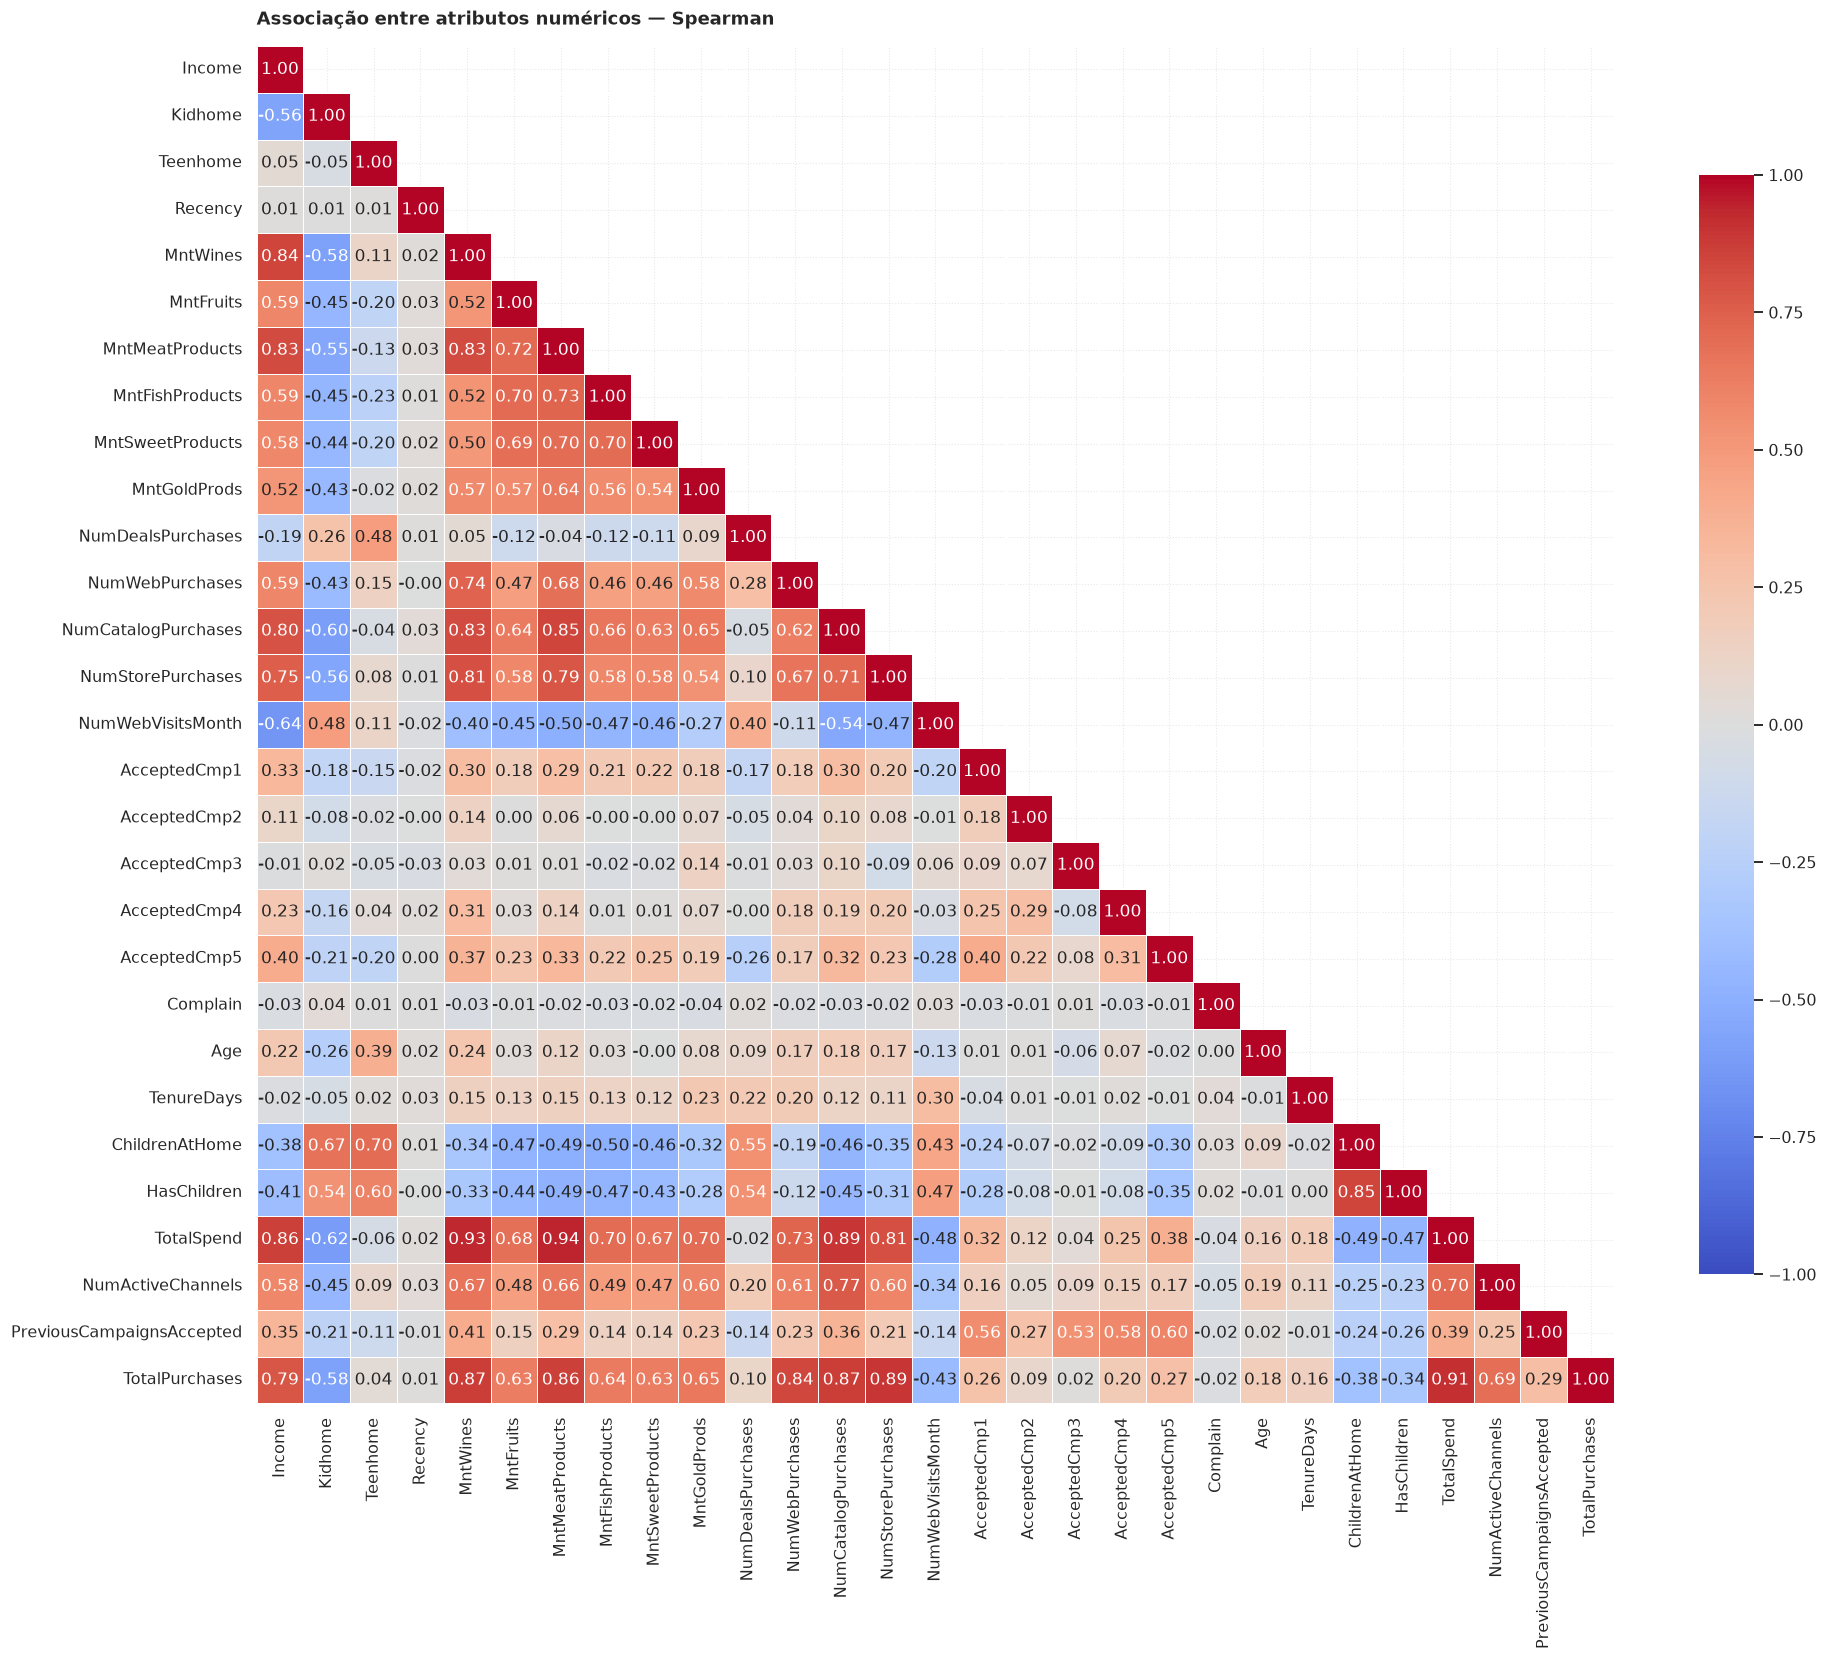

In [16]:
# Visualização da matriz de Spearman
fig, ax = plt.subplots(figsize=(18, 15))

mask = np.triu(
    np.ones_like(spearman_matrix, dtype=bool),
    k=1
)
sns.heatmap(
    spearman_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.35,
    cbar_kws={"shrink": 0.8},
    ax=ax
)

ax.set_title("Associação entre atributos numéricos — Spearman", loc="left", pad=14)
plt.tight_layout()
plt.show()

In [17]:
# Top 30 pares por intensidade absoluta
display(
    spearman_pairs.head(30)[
        ["Feature_1", "Feature_2", "Spearman", "N_Observations"]
    ].style.format({"Spearman": "{:.3f}"})
)

,Feature_1,Feature_2,Spearman,N_Observations
0,MntMeatProducts,TotalSpend,0.939,2229
1,MntWines,TotalSpend,0.931,2229
2,TotalSpend,TotalPurchases,0.908,2229
3,NumStorePurchases,TotalPurchases,0.892,2229
4,NumCatalogPurchases,TotalSpend,0.891,2229
5,MntWines,TotalPurchases,0.872,2229
6,NumCatalogPurchases,TotalPurchases,0.870,2229
7,Income,TotalSpend,0.860,2205
8,MntMeatProducts,TotalPurchases,0.860,2229
9,ChildrenAtHome,HasChildren,0.851,2229


### Síntese

Entre os pares com maiores associações na base atual, destacam-se:

| Relação | Spearman | Interpretação |
|---|---:|---|
| `MntMeatProducts` × `TotalSpend` | 0,939 | Forte associação entre uma categoria e o gasto agregado. |
| `MntWines` × `TotalSpend` | 0,931 | Forte associação entre uma categoria e o gasto agregado. |
| `TotalSpend` × `TotalPurchases` | 0,908 | Associação entre o volume financeiro e a quantidade de compras. |
| `NumStorePurchases` × `TotalPurchases` | 0,892 | Associação entre um canal de compra e a quantidade total de compras. |
| `NumCatalogPurchases` × `TotalSpend` | 0,891 | Associação entre compras por catálogo e gasto total. |
| `NumCatalogPurchases` × `TotalPurchases` | 0,870 | Associação entre um canal de compra e a quantidade total de compras. |
| `Income` × `TotalSpend` | 0,860 | Associação empírica entre renda e gasto total. |
| `ChildrenAtHome` × `HasChildren` | 0,851 | A variável binária representa a presença de filhos, simplificando a informação sobre sua quantidade. |

Parte das associações mais elevadas é esperada pela construção das variáveis derivadas. `TotalSpend` agrega os valores das categorias de consumo, `TotalPurchases` reúne as quantidades de compras por canal e `ChildrenAtHome` representa a soma de `Kidhome` e `Teenhome`. Já `HasChildren` transforma essa quantidade em uma indicação binária.

Essas relações entre componentes e agregados não devem ser interpretadas como evidências independentes de associação ou como motivo automático para exclusão de variáveis.

Também aparecem associações empíricas entre renda, consumo e canais de compra. Por exemplo, `Income` apresenta correlação de 0,860 com `TotalSpend`. Essas relações indicam que as dimensões não são estatisticamente independentes, mas não demonstram causalidade ou que uma variável possa substituir outra sem perda de informação.

O Top 30 apresenta apenas os pares com maior intensidade absoluta de correlação de Spearman. A ausência de uma variável nessa seleção não significa ausência de associação.

## 4. Associações direcionadas por origem e construção

A matriz geral ajuda a localizar relações relevantes entre as features. Nesta seção, a análise é direcionada a três grupos em que a origem e a construção das variáveis justificam uma investigação mais detalhada:

- composição familiar;
- categorias originais de consumo;
- flags individuais de aceitação de campanhas e sua agregação.

O objetivo é distinguir relações esperadas pela construção das features de associações empíricas entre variáveis que representam dimensões distintas.

In [18]:
# Definição dos grupos e pares de features para as análises direcionadas
family_features = [
    "Kidhome",
    "Teenhome",
    "ChildrenAtHome",
    "HasChildren",
]

spend_features = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
]

campaign_features = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
]

# Pares da dimensão familiar
family_pairs = list(combinations(family_features, 2))

# Pares entre as seis categorias originais de consumo
spend_pairs = list(combinations(spend_features, 2))

# Pares entre flags de campanha e cada flag com o agregado
campaign_pairs = list(combinations(campaign_features, 2)) + [
    (col, "PreviousCampaignsAccepted")
    for col in campaign_features
]

analysis_groups = {
    "Composição familiar": family_pairs,
    "Categorias de consumo": spend_pairs,
    "Histórico de campanhas": campaign_pairs,
}

In [19]:
# Cálculo das associações direcionadas entre os pares selecionados
directed_records = []

for group_name, pairs in analysis_groups.items():
    for col1, col2 in pairs:
        pair_data = features_df[[col1, col2]].dropna()

        if len(pair_data) < 2:
            continue
        if pair_data[col1].nunique() < 2 or pair_data[col2].nunique() < 2:
            rho = np.nan
        else:
            rho, _ = spearmanr(pair_data[col1], pair_data[col2])

        directed_records.append({
            "Dimension": group_name,
            "Feature_1": col1,
            "Feature_2": col2,
            "Spearman": rho,
            "N_Observations": len(pair_data),
        })

In [20]:
# Consolidação e apresentação das associações por dimensão
directed_associations = pd.DataFrame(directed_records)

for group_name in analysis_groups:
    print(f"\n{group_name}")
    display(
        directed_associations.loc[
            directed_associations["Dimension"].eq(group_name),
            ["Feature_1", "Feature_2", "Spearman", "N_Observations"]
        ]
        .sort_values("Spearman", key=lambda values: values.abs(), ascending=False)
        .style.format({"Spearman": "{:.3f}"})
    )


Composição familiar


,Feature_1,Feature_2,Spearman,N_Observations
5,ChildrenAtHome,HasChildren,0.851,2229
3,Teenhome,ChildrenAtHome,0.698,2229
1,Kidhome,ChildrenAtHome,0.673,2229
4,Teenhome,HasChildren,0.604,2229
2,Kidhome,HasChildren,0.535,2229
0,Kidhome,Teenhome,-0.047,2229



Categorias de consumo


,Feature_1,Feature_2,Spearman,N_Observations
7,MntWines,MntMeatProducts,0.827,2229
15,MntMeatProducts,MntFishProducts,0.730,2229
11,MntFruits,MntMeatProducts,0.716,2229
12,MntFruits,MntFishProducts,0.705,2229
18,MntFishProducts,MntSweetProducts,0.701,2229
16,MntMeatProducts,MntSweetProducts,0.699,2229
13,MntFruits,MntSweetProducts,0.691,2229
17,MntMeatProducts,MntGoldProds,0.642,2229
10,MntWines,MntGoldProds,0.573,2229
14,MntFruits,MntGoldProds,0.567,2229



Histórico de campanhas


,Feature_1,Feature_2,Spearman,N_Observations
35,AcceptedCmp5,PreviousCampaignsAccepted,0.596,2229
34,AcceptedCmp4,PreviousCampaignsAccepted,0.583,2229
31,AcceptedCmp1,PreviousCampaignsAccepted,0.560,2229
33,AcceptedCmp3,PreviousCampaignsAccepted,0.534,2229
24,AcceptedCmp1,AcceptedCmp5,0.404,2229
30,AcceptedCmp4,AcceptedCmp5,0.308,2229
26,AcceptedCmp2,AcceptedCmp4,0.292,2229
32,AcceptedCmp2,PreviousCampaignsAccepted,0.273,2229
23,AcceptedCmp1,AcceptedCmp4,0.251,2229
27,AcceptedCmp2,AcceptedCmp5,0.222,2229


### Síntese

**Composição familiar.** `Kidhome` e `Teenhome` apresentam correlação baixa entre si (Spearman de -0,047), indicando associação monotônica praticamente inexistente na amostra. Ambas se relacionam com `ChildrenAtHome`, construído pela soma das duas variáveis. O agregado preserva a quantidade total de filhos no domicílio, mas não distingue sua composição etária. `HasChildren`, por sua vez, reduz essa informação a uma representação binária de presença ou ausência de filhos. As associações entre essas variáveis derivadas e suas componentes são esperadas pela própria construção.

**Consumo.** As seis categorias apresentam associações positivas entre si, com destaque para `MntWines` × `MntMeatProducts` (0,827) e `MntMeatProducts` × `MntFishProducts` (0,730). Apesar das associações observadas, cada categoria representa uma dimensão específica do consumo. Portanto, a correlação não determina, isoladamente, redundância ou necessidade de exclusão das variáveis.

**Campanhas.** As flags individuais apresentam associações de intensidades diferentes entre si. As correlações entre cada flag e `PreviousCampaignsAccepted` variam de 0,273 (`AcceptedCmp2`) a 0,596 (`AcceptedCmp5`). Como o agregado resume a quantidade de campanhas aceitas a partir dessas mesmas flags, as associações com a variável derivada são esperadas pela construção matemática. O agregado representa o volume de aceitações anteriores, mas não preserva a identidade das campanhas.

## 5. Associações entre variáveis categóricas — V de Cramér

O V de Cramér mede a intensidade da associação entre duas variáveis categóricas a partir de uma tabela de contingência. É uma medida não direcional, com valores entre 0 e 1, em que valores próximos de zero indicam associações fracas e valores próximos de um indicam associações fortes.

A implementação utiliza a correção de viés para amostras finitas. Os pares foram selecionados com base na origem e na construção das features, além de relações de interesse identificadas durante a EDA.

In [21]:
# Cálculo do V de Cramér para os pares categóricos selecionados
categorical_pairs = [
    ("Marital_Status", "FamilyProfile"),
    ("HasChildren", "FamilyProfile"),
    ("Education", "IncomeGroup"),
    ("PreferredChannel", "Education"),
    ("PreferredChannel", "Marital_Status"),
    ("PreferredChannel", "FamilyProfile"),
    ("WebVisitsGroup", "PreferredChannel"),
    ("AgeGroup", "Marital_Status"),
    ("TenureGroup", "RecencyGroup"),
]

cramers_records = []

for col1, col2 in categorical_pairs:
    pair_data = features_df[[col1, col2]].dropna()

    cramers_records.append({
        "Feature_1": col1,
        "Feature_2": col2,
        "Cramers_V": cramers_v(pair_data[col1], pair_data[col2]),
        "N_Observations": len(pair_data),
        "Categories_1": pair_data[col1].nunique(),
        "Categories_2": pair_data[col2].nunique(),
    })

cramers_results = (
    pd.DataFrame(cramers_records)
    .sort_values("Cramers_V", ascending=False)
    .reset_index(drop=True)
)

display(
    cramers_results.style.format({"Cramers_V": "{:.3f}"})
)

,Feature_1,Feature_2,Cramers_V,N_Observations,Categories_1,Categories_2
0,Marital_Status,FamilyProfile,0.999,2229,4,8
1,HasChildren,FamilyProfile,0.999,2229,2,8
2,WebVisitsGroup,PreferredChannel,0.252,2229,4,5
3,Education,IncomeGroup,0.174,2205,5,4
4,PreferredChannel,FamilyProfile,0.149,2229,5,8
5,AgeGroup,Marital_Status,0.137,2229,4,4
6,PreferredChannel,Marital_Status,0.033,2229,5,4
7,PreferredChannel,Education,0.023,2229,5,5
8,TenureGroup,RecencyGroup,0.020,2229,4,4


### Síntese

Os resultados mostram associações de intensidades distintas entre os pares selecionados:

| Relação | V de Cramér | Interpretação |
|---|---:|---|
| `Marital_Status` × `FamilyProfile` | 0,999 | Associação esperada: o perfil familiar incorpora o estado civil. |
| `HasChildren` × `FamilyProfile` | 0,999 | Associação esperada: o perfil familiar incorpora a presença de filhos. |
| `WebVisitsGroup` × `PreferredChannel` | 0,252 | Associação mais expressiva entre os pares empíricos avaliados. |
| `Education` × `IncomeGroup` | 0,174 | Associação entre escolaridade e faixa de renda. |
| `PreferredChannel` × `FamilyProfile` | 0,149 | Associação fraca entre perfil familiar e canal preferencial. |
| `AgeGroup` × `Marital_Status` | 0,137 | Associação fraca entre faixa etária e estado civil. |
| `PreferredChannel` × `Marital_Status` | 0,033 | Associação muito fraca. |
| `PreferredChannel` × `Education` | 0,023 | Associação muito fraca. |
| `TenureGroup` × `RecencyGroup` | 0,020 | Associação muito fraca entre as representações categóricas. |

Os valores próximos de 1,00 entre `FamilyProfile` e seus componentes decorrem da própria regra de construção da variável composta. Não representam descobertas independentes sobre o comportamento dos clientes e indicam forte sobreposição de informação entre essas features.

Entre os demais pares, `WebVisitsGroup` × `PreferredChannel` apresenta a associação mais expressiva. Os resultados sugerem uma relação entre engajamento digital e canal preferencial, embora não indiquem direção ou causalidade.

As demais associações apresentam baixa intensidade na representação categórica utilizada. Em particular, a associação muito fraca entre `TenureGroup` e `RecencyGroup` indica que essas duas dimensões temporais não apresentam dependência relevante após o agrupamento adotado.

O V de Cramér mede apenas a intensidade da associação. Portanto, não indica direção, causalidade ou contribuição preditiva individual. Os resultados devem ser interpretados como evidências descritivas da amostra.

## 6. Análise da construção e representação das features derivadas

Esta seção investiga a origem, a construção e a informação preservada pelas variáveis derivadas. As análises comparam representações agregadas, categóricas e compostas com suas variáveis de origem, identificando sobreposições e limitações informacionais.

A análise da informação preservada ou perdida contribui para avaliar a adequação de diferentes representações às aplicações de segmentação e modelagem preditiva, mas não comprova, por si só, sua contribuição ou desempenho nos modelos.

### 6.1 Composição familiar

`ChildrenAtHome` soma `Kidhome` e `Teenhome`. `HasChildren` indica se essa soma é maior que zero. `FamilyProfile` combina `Marital_Status` com a presença ou ausência de filhos.

A análise das composições permite identificar quantas combinações distintas de crianças e adolescentes são observadas para cada quantidade total de filhos.

In [22]:
# Composições distintas para cada quantidade total de filhos
family_compositions = summarize_compositions(
    features_df,
    group_col="ChildrenAtHome",
    component_cols=["Kidhome", "Teenhome"]
)

display(family_compositions)

,ChildrenAtHome,n_distinct_compositions,n_clients
0,0,1,633
1,1,2,1123
2,2,3,420
3,3,2,53


#### Síntese

Na base atual, a mesma quantidade total de filhos pode corresponder a diferentes combinações de crianças e adolescentes. Para `ChildrenAtHome = 1`, foram observadas duas composições; para `ChildrenAtHome = 2`, três.

`ChildrenAtHome` preserva a quantidade total, mas perde a distinção entre crianças e adolescentes. `HasChildren` reduz ainda mais essa informação, preservando apenas a presença ou ausência de filhos.

`FamilyProfile` combina estado civil e presença de filhos em uma categoria composta. Embora seus componentes possam ser recuperados a partir dos rótulos atuais, a variável representa a combinação conjunta dessas dimensões.

### 6.2 Consumo por categoria e gasto total

`TotalSpend` corresponde à soma das seis variáveis de consumo (`Mnt*`). A análise identifica quantas composições distintas dessas categorias podem resultar em cada valor de gasto total.

In [23]:
# Composições distintas para cada valor de gasto total

spend_compositions = summarize_compositions(
    features_df,
    group_col="TotalSpend",
    component_cols=spend_features
)

multiple_spend_totals = spend_compositions.loc[
    spend_compositions["n_distinct_compositions"] > 1
]

In [24]:
# Consolidação das métricas de composição do gasto total
spend_summary = pd.DataFrame({
    "Métrica": [
        "Valores distintos de TotalSpend",
        "Valores com múltiplas composições",
        "Percentual de valores com múltiplas composições",
        "Clientes associados a esses valores",
    ],
    "Valor": [
        len(spend_compositions),
        len(multiple_spend_totals),
        len(multiple_spend_totals) / len(spend_compositions) * 100,
        multiple_spend_totals["n_clients"].sum(),
    ],
})

display(spend_summary)

,Métrica,Valor
0,Valores distintos de TotalSpend,"1,052.00"
1,Valores com múltiplas composições,401.00
2,Percentual de valores com múltiplas composições,38.12
3,Clientes associados a esses valores,"1,519.00"


#### Síntese

Na base atual, existem 1.052 valores distintos de gasto total; 401 deles (38,12%) admitem mais de uma composição de categorias. Os clientes associados a esses totais somam 1.519.

Portanto, `TotalSpend` preserva o volume monetário agregado, mas não permite recuperar como o gasto foi distribuído entre vinhos, frutas, carnes, peixes, doces e produtos de ouro. As seis variáveis originais preservam a composição específica do consumo e não são substituídas integralmente pelo total.

### 6.3 Compras por canal e amplitude de utilização

`TotalPurchases` soma as compras realizadas pela internet, em loja física e por catálogo. `NumActiveChannels` conta quantos desses canais possuem pelo menos uma compra. `PreferredChannel` identifica o canal com maior volume; empates e ausência de compras recebem categorias próprias.

As três representações descrevem dimensões diferentes: volume total, quantidade de canais ativos e canal predominante.

In [25]:
# Definição das features de compras por canal utilizadas na análise
purchase_features = [
    "NumWebPurchases",
    "NumStorePurchases",
    "NumCatalogPurchases",
]

In [26]:
# Composições distintas para cada total de compras
purchase_compositions = summarize_compositions(
    features_df,
    group_col="TotalPurchases",
    component_cols=purchase_features
)

multiple_purchase_totals = purchase_compositions.loc[
    purchase_compositions["n_distinct_compositions"] > 1
]

In [27]:
# Consolidação das métricas de composição das compras por canal
purchase_summary = pd.DataFrame({
    "Métrica": [
        "Valores distintos de TotalPurchases",
        "Valores com múltiplas composições",
        "Percentual de valores com múltiplas composições",
        "Clientes associados a esses valores",
    ],
    "Valor": [
        purchase_compositions["TotalPurchases"].nunique(),
        len(multiple_purchase_totals),
        len(multiple_purchase_totals) / len(purchase_compositions) * 100,
        multiple_purchase_totals["n_clients"].sum(),
    ],
})

display(purchase_summary)

,Métrica,Valor
0,Valores distintos de TotalPurchases,33.00
1,Valores com múltiplas composições,31.00
2,Percentual de valores com múltiplas composições,93.94
3,Clientes associados a esses valores,"2,224.00"


In [28]:
# Composições distintas para cada quantidade de canais ativos

channel_compositions = summarize_compositions(
    features_df,
    group_col="NumActiveChannels",
    component_cols=purchase_features
)

display(channel_compositions)

,NumActiveChannels,n_distinct_compositions,n_clients
0,0,1,4
1,1,7,37
2,2,16,549
3,3,575,1639


In [29]:
# Distribuição da preferência predominante

display(
    features_df["PreferredChannel"]
    .value_counts(dropna=False)
    .rename("Número de clientes")
    .to_frame()
)

,Número de clientes
PreferredChannel,
Store,1476
Web,325
Tied Channels,291
Catalog,133
No Purchases,4


#### Síntese

Na base atual, 31 dos 33 valores distintos de `TotalPurchases` (93,94%) admitem múltiplas composições de compras entre os três canais. Esses totais abrangem 2.224 clientes, demonstrando que quantidades iguais de compras podem corresponder a diferentes distribuições entre os canais.

A distribuição de `NumActiveChannels` mostra que 1.639 clientes utilizam os três canais, 549 utilizam dois, 37 utilizam apenas um e quatro não apresentam compras. Mesmo entre os clientes que utilizam os três canais, foram observadas 575 composições distintas de volumes de compras.

Em relação ao canal predominante, há concentração em `Store`, com 1.476 clientes, seguido por `Web` (325), `Tied Channels` (291), `Catalog` (133) e `No Purchases` (4).

Assim, `TotalPurchases`, `NumActiveChannels` e `PreferredChannel` representam dimensões complementares do comportamento de compra. Nenhuma dessas variáveis preserva isoladamente todas as informações contidas nas três variáveis originais de compras por canal.

### 6.4 Histórico de aceitação de campanhas

`PreviousCampaignsAccepted` soma as cinco flags `AcceptedCmp1` a `AcceptedCmp5`. A análise investiga quantas combinações distintas de campanhas podem resultar em cada total de aceitações e compara a frequência de aceitação das campanhas individuais.

In [30]:
# Composições distintas para cada total de campanhas aceitas
campaign_compositions = summarize_compositions(
    features_df,
    group_col="PreviousCampaignsAccepted",
    component_cols=campaign_features
)

multiple_campaign_totals = campaign_compositions.loc[
    campaign_compositions["n_distinct_compositions"] > 1
]

display(campaign_compositions)

,PreviousCampaignsAccepted,n_distinct_compositions,n_clients
0,0,1,1767
1,1,5,324
2,2,7,83
3,3,5,44
4,4,2,11


In [31]:
# Resumo das composições de campanhas
campaign_summary = pd.DataFrame({
    "Métrica": [
        "Totais distintos de campanhas aceitas",
        "Totais com múltiplas composições",
        "Clientes em totais com múltiplas composições",
        "Percentual de clientes nesses totais",
        "Clientes sem aceitação anterior",
    ],
    "Valor": [
        len(campaign_compositions),
        len(multiple_campaign_totals),
        multiple_campaign_totals["n_clients"].sum(),
        multiple_campaign_totals["n_clients"].sum()
            / len(features_df) * 100,
        features_df["PreviousCampaignsAccepted"].eq(0).sum(),
    ],
})

display(campaign_summary.round(2))

,Métrica,Valor
0,Totais distintos de campanhas aceitas,5.00
1,Totais com múltiplas composições,4.00
2,Clientes em totais com múltiplas composições,462.00
3,Percentual de clientes nesses totais,20.73
4,Clientes sem aceitação anterior,"1,767.00"


In [32]:
# Frequência de aceitação de cada campanha individual
campaign_frequency = (
    features_df[campaign_features]
    .sum()
    .rename("Clientes que aceitaram")
    .to_frame()
)

campaign_frequency["Taxa de aceitação (%)"] = (
    campaign_frequency["Clientes que aceitaram"]
    / len(features_df) * 100
)

display(
    campaign_frequency.style.format({
        "Clientes que aceitaram": "{:,.0f}",
        "Taxa de aceitação (%)": "{:.2f}%",
    })
)

,Clientes que aceitaram,Taxa de aceitação (%)
AcceptedCmp1,144,6.46%
AcceptedCmp2,30,1.35%
AcceptedCmp3,163,7.31%
AcceptedCmp4,167,7.49%
AcceptedCmp5,162,7.27%


#### Síntese

Na base atual, `PreviousCampaignsAccepted` apresenta cinco valores distintos, de zero a quatro campanhas aceitas. Quatro desses cinco totais admitem múltiplas combinações de campanhas, abrangendo 462 clientes (20,73% da amostra). Os outros 1.767 clientes (79,27%) não apresentam aceitação em nenhuma das cinco campanhas.

A frequência individual varia entre as campanhas. `AcceptedCmp2` apresenta a menor taxa de aceitação (1,35%), enquanto as demais ficam entre 6,46% e 7,49%.

A variável agregada representa a quantidade acumulada de campanhas aceitas, mas perde a identidade das campanhas. As flags individuais preservam essa informação e permitem distinguir os diferentes históricos de aceitação.

### 6.5 Renda e `IncomeGroup`

`IncomeGroup` divide `Income` em quatro grupos definidos por quartis (`pd.qcut`). A análise caracteriza a distribuição dos clientes e os intervalos de renda abrangidos por cada grupo.

Os 24 registros sem `Income` permanecem sem classificação; não há imputação nesta etapa.

In [33]:
# Distribuição de clientes por grupo de renda

income_distribution = (
    features_df["IncomeGroup"]
    .value_counts(dropna=False)
    .rename("Número de clientes")
    .rename_axis("Grupo de renda")
    .reset_index()
)

display(
    income_distribution.style.format(
        {"Número de clientes": "{:,.0f}"},
        na_rep="—"
    )
)

,Grupo de renda,Número de clientes
0,Low,553
1,Medium-High,551
2,High,551
3,Medium-Low,550
4,—,24


In [34]:
# Caracterização dos grupos de renda
income_compositions = (
    features_df
    .dropna(subset=["Income"])
    .groupby("IncomeGroup", observed=True)
    .agg(
        Valores_distintos=("Income", "nunique"),
        Renda_minima=("Income", "min"),
        Renda_maxima=("Income", "max"),
    )
    .reset_index()
)

display(income_compositions)

,IncomeGroup,Valores_distintos,Renda_minima,Renda_maxima
0,Low,481,"1,730.00","35,196.00"
1,Medium-Low,489,"35,246.00","51,287.00"
2,Medium-High,498,"51,315.00","68,281.00"
3,High,495,"68,316.00","113,734.00"


#### Síntese

Os quatro grupos apresentam quantidades próximas de clientes: 553 em `Low`, 550 em `Medium-Low`, 551 em `Medium-High` e 551 em `High`. Outros 24 registros permanecem sem classificação devido à ausência de renda.

Cada grupo reúne diversos valores distintos de renda, demonstrando que a categorização agrega clientes com magnitudes diferentes dentro de uma mesma faixa.

`Income` preserva a magnitude contínua da renda, enquanto `IncomeGroup` representa sua posição aproximada na distribuição. A categorização facilita a interpretação por faixas, mas perde a magnitude exata e as diferenças de renda entre clientes pertencentes ao mesmo grupo.

### 6.6 Idade e `AgeGroup`

`AgeGroup` agrupa `Age` em quatro faixas definidas por intervalos: 18–30, 31–45, 46–60 e 61 anos ou mais. A análise caracteriza a distribuição dos clientes e a amplitude das idades representadas em cada grupo.

In [35]:
# Caracterização dos grupos etários

age_group_summary = summarize_numeric_groups(
    features_df,
    group_col="AgeGroup",
    value_col="Age"
)

display(
    age_group_summary.rename(columns={
        "AgeGroup": "Faixa etária",
        "n_clients": "Número de clientes",
        "n_distinct_values": "Idades distintas",
        "min_value": "Idade mínima",
        "max_value": "Idade máxima",
    })
)

,Faixa etária,Número de clientes,Idades distintas,Idade mínima,Idade máxima
0,18-30,259,13,18,30
1,31-45,969,15,31,45
2,46-60,736,15,46,60
3,61+,265,13,61,74


#### Síntese

Na base atual, a faixa de 31–45 anos reúne 969 clientes (43,47%), seguida por 46–60 anos (736), 61 anos ou mais (265) e 18–30 anos (259).

A variável derivada reduz 56 idades distintas a quatro categorias. Essa representação facilita a interpretação por faixa etária, mas não preserva a idade exata nem as diferenças entre clientes pertencentes ao mesmo intervalo.

`Age` mantém a informação contínua e sua granularidade original, enquanto `AgeGroup` oferece uma representação categórica mais agregada.

### 6.7 Tempo de relacionamento e recência

`TenureGroup` divide `TenureDays` em quatro grupos de tamanho semelhante, definidos por quartis. `RecencyGroup` organiza `Recency` em quatro intervalos fixos: até 30 dias, 31–60, 61–90 e mais de 90 dias.

Embora ambas sejam medidas de tempo expressas em dias, representam dimensões diferentes: tempo de relacionamento e tempo desde a última compra.

In [36]:
# Caracterização dos grupos de tempo de relacionamento

tenure_summary = summarize_numeric_groups(
    features_df,
    group_col="TenureGroup",
    value_col="TenureDays"
)

display(
    tenure_summary.rename(columns={
        "TenureGroup": "Grupo de relacionamento",
        "n_clients": "Número de clientes",
        "n_distinct_values": "Valores distintos",
        "min_value": "Mínimo de dias",
        "max_value": "Máximo de dias",
    })
)

,Grupo de relacionamento,Número de clientes,Valores distintos,Mínimo de dias,Máximo de dias
0,New,560,171,0,181
1,Short,558,166,182,356
2,Long,558,162,357,529
3,Very Long,553,164,530,699


In [37]:
# Caracterização dos grupos de recência

recency_summary = summarize_numeric_groups(
    features_df,
    group_col="RecencyGroup",
    value_col="Recency"
)

display(
    recency_summary.rename(columns={
        "RecencyGroup": "Grupo de recência",
        "n_clients": "Número de clientes",
        "n_distinct_values": "Valores distintos",
        "min_value": "Mínimo de dias",
        "max_value": "Máximo de dias",
    })
)

,Grupo de recência,Número de clientes,Valores distintos,Mínimo de dias,Máximo de dias
0,Up to 30 days,720,31,0,30
1,31-60 days,651,30,31,60
2,61-90 days,662,30,61,90
3,Over 90 days,196,9,91,99


#### Síntese

`TenureGroup` distribui os clientes em quatro grupos de tamanho aproximadamente semelhante, preservando sua posição relativa na distribuição do tempo de relacionamento. Essa categorização facilita a comparação entre faixas, mas perde a quantidade exata de dias de cada cliente.

`RecencyGroup` apresenta a seguinte distribuição: 720 clientes até 30 dias, 651 entre 31 e 60 dias, 662 entre 61 e 90 dias e 196 acima de 90 dias. A variável transforma a recência contínua em intervalos fixos, facilitando a identificação de grupos conforme o tempo desde a última compra.

`TenureDays` e `Recency` representam dimensões temporais distintas. A primeira mede o tempo de relacionamento acumulado com a empresa; a segunda, o tempo transcorrido desde a última compra. Portanto, não devem ser consideradas redundantes apenas por utilizarem a mesma unidade de medida.

### 6.8 Engajamento digital e `WebVisitsGroup`

`WebVisitsGroup` agrupa `NumWebVisitsMonth` em quatro faixas: 0–2, 3–5, 6–8 e 9 ou mais visitas. A análise caracteriza a distribuição dos clientes e a amplitude dos valores representados em cada grupo.

In [38]:
# Caracterização dos grupos de visitas digitais

web_visits_summary = summarize_numeric_groups(
    features_df,
    group_col="WebVisitsGroup",
    value_col="NumWebVisitsMonth"
)

display(
    web_visits_summary.rename(columns={
        "WebVisitsGroup": "Faixa de visitas",
        "n_clients": "Número de clientes",
        "n_distinct_values": "Valores distintos",
        "min_value": "Mínimo de visitas",
        "max_value": "Máximo de visitas",
    })
)

,Faixa de visitas,Número de clientes,Valores distintos,Mínimo de visitas,Máximo de visitas
0,0–2 visits,358,3,0,2
1,3–5 visits,702,3,3,5
2,6–8 visits,1074,3,6,8
3,9+ visits,95,7,9,20


#### Síntese

Na base atual, a faixa de 6–8 visitas concentra 1.074 clientes (48,18%), seguida por 3–5 visitas (702), 0–2 visitas (358) e nove ou mais visitas (95).

A faixa aberta de nove ou mais visitas reúne sete valores distintos, de 9 a 20. A categorização facilita a interpretação dos níveis de engajamento digital, mas perde a quantidade exata de visitas e as diferenças entre clientes pertencentes à mesma faixa.

`NumWebVisitsMonth` preserva a quantidade original de visitas, enquanto `WebVisitsGroup` oferece uma representação categórica mais agregada.

## 7. Consolidação da origem, construção e representação informacional

O quadro a seguir reúne as 13 variáveis derivadas, suas variáveis de origem, as transformações aplicadas e o tipo de informação preservada ou não representada em cada caso.

O inventário documenta a linhagem e as características informacionais das features, consolidando as evidências das análises anteriores. Não determina quais variáveis devem ser mantidas ou removidas dos conjuntos destinados à segmentação e à modelagem preditiva.

In [39]:
# Consolidação da linhagem e das transformações das features derivadas
feature_lineage = pd.DataFrame([
    {
        "Derived_Feature": "ChildrenAtHome",
        "Source_Features": "Kidhome + Teenhome",
        "Transformation": "Soma das quantidades",
        "Preserves": "Quantidade total de filhos no domicílio",
        "Information_Limitation": "Não distingue crianças de adolescentes",
    },
    {
        "Derived_Feature": "HasChildren",
        "Source_Features": "ChildrenAtHome",
        "Transformation": "Indicador: total > 0",
        "Preserves": "Presença ou ausência de filhos",
        "Information_Limitation": "Não preserva a quantidade de filhos",
    },
    {
        "Derived_Feature": "FamilyProfile",
        "Source_Features": "Marital_Status + HasChildren",
        "Transformation": "Combinação categórica das duas dimensões",
        "Preserves": "Perfil conjunto de estado civil e presença de filhos",
        "Information_Limitation": "Representa os componentes em categorias conjuntas, em vez de mantê-los em colunas independentes.",
    },
    {
        "Derived_Feature": "IncomeGroup",
        "Source_Features": "Income",
        "Transformation": "Discretização em quartis",
        "Preserves": "Posição aproximada na distribuição de renda",
        "Information_Limitation": "Perde a magnitude exata da renda; ausências são mantidas",
    },
    {
        "Derived_Feature": "AgeGroup",
        "Source_Features": "Age",
        "Transformation": "Faixas etárias fixas",
        "Preserves": "Faixa etária do cliente",
        "Information_Limitation": "Perde a idade exata e diferenças dentro da faixa",
    },
    {
        "Derived_Feature": "TotalSpend",
        "Source_Features": "Seis variáveis Mnt*",
        "Transformation": "Soma dos gastos por categoria",
        "Preserves": "Volume monetário total de consumo",
        "Information_Limitation": "Perde a composição dos gastos por categoria",
    },
    {
        "Derived_Feature": "PreferredChannel",
        "Source_Features": "NumWebPurchases + NumStorePurchases + NumCatalogPurchases",
        "Transformation": "Canal com maior volume; empate e ausência de compras têm categorias próprias",
        "Preserves": "Canal predominante ou empate no maior volume",
        "Information_Limitation": "Não preserva volumes nem composição completa entre canais",
    },
    {
        "Derived_Feature": "NumActiveChannels",
        "Source_Features": "NumWebPurchases + NumStorePurchases + NumCatalogPurchases",
        "Transformation": "Contagem de canais com pelo menos uma compra",
        "Preserves": "Quantidade de canais efetivamente utilizados",
        "Information_Limitation": "Não identifica quais canais nem o volume em cada um",
    },
    {
        "Derived_Feature": "PreviousCampaignsAccepted",
        "Source_Features": "AcceptedCmp1 a AcceptedCmp5",
        "Transformation": "Soma das flags de aceitação",
        "Preserves": "Quantidade de campanhas aceitas",
        "Information_Limitation": "Perde a identidade das campanhas aceitas",
    },
    {
        "Derived_Feature": "WebVisitsGroup",
        "Source_Features": "NumWebVisitsMonth",
        "Transformation": "Faixas de visitas mensais",
        "Preserves": "Intervalo de frequência de visitas",
        "Information_Limitation": "Perde a quantidade exata de visitas",
    },
    {
        "Derived_Feature": "TenureGroup",
        "Source_Features": "TenureDays",
        "Transformation": "Discretização em quartis",
        "Preserves": "Posição relativa no tempo de relacionamento",
        "Information_Limitation": "Perde a quantidade exata de dias",
    },
    {
        "Derived_Feature": "RecencyGroup",
        "Source_Features": "Recency",
        "Transformation": "Faixas fixas de dias desde a última compra",
        "Preserves": "Intervalo de recência",
        "Information_Limitation": "Perde a quantidade exata de dias",
    },
    {
        "Derived_Feature": "TotalPurchases",
        "Source_Features": "NumWebPurchases + NumStorePurchases + NumCatalogPurchases",
        "Transformation": "Soma das compras nos três canais",
        "Preserves": "Volume total de compras",
        "Information_Limitation": "Perde a distribuição das compras entre canais",
    },
])

display(
    feature_lineage.rename(columns={
        "Derived_Feature": "Feature derivada",
        "Source_Features": "Variáveis de origem",
        "Transformation": "Transformação",
        "Preserves": "Informação preservada",
        "Information_Limitation": "Limitação informacional",
    })
)

,Feature derivada,Variáveis de origem,Transformação,Informação preservada,Limitação informacional
0,ChildrenAtHome,Kidhome + Teenhome,Soma das quantidades,Quantidade total de filhos no domicílio,Não distingue crianças de adolescentes
1,HasChildren,ChildrenAtHome,Indicador: total > 0,Presença ou ausência de filhos,Não preserva a quantidade de filhos
2,FamilyProfile,Marital_Status + HasChildren,Combinação categórica das duas dimensões,Perfil conjunto de estado civil e presença de ...,Representa os componentes em categorias conjun...
3,IncomeGroup,Income,Discretização em quartis,Posição aproximada na distribuição de renda,Perde a magnitude exata da renda; ausências sã...
4,AgeGroup,Age,Faixas etárias fixas,Faixa etária do cliente,Perde a idade exata e diferenças dentro da faixa
5,TotalSpend,Seis variáveis Mnt*,Soma dos gastos por categoria,Volume monetário total de consumo,Perde a composição dos gastos por categoria
6,PreferredChannel,NumWebPurchases + NumStorePurchases + NumCatal...,Canal com maior volume; empate e ausência de c...,Canal predominante ou empate no maior volume,Não preserva volumes nem composição completa e...
7,NumActiveChannels,NumWebPurchases + NumStorePurchases + NumCatal...,Contagem de canais com pelo menos uma compra,Quantidade de canais efetivamente utilizados,Não identifica quais canais nem o volume em ca...
8,PreviousCampaignsAccepted,AcceptedCmp1 a AcceptedCmp5,Soma das flags de aceitação,Quantidade de campanhas aceitas,Perde a identidade das campanhas aceitas
9,WebVisitsGroup,NumWebVisitsMonth,Faixas de visitas mensais,Intervalo de frequência de visitas,Perde a quantidade exata de visitas


In [40]:
# Base Features sem representação derivada direta

base_without_direct_aggregate = [
    "Education",
    "NumDealsPurchases",
    "Complain",
]

display(
    pd.DataFrame({
        "Base Feature": base_without_direct_aggregate
    })
)

,Base Feature
0,Education
1,NumDealsPurchases
2,Complain


## 8. Síntese das análises estruturais

A avaliação identificou três padrões principais na origem e representação das features:

**1. Agregação.** `TotalSpend`, `TotalPurchases`, `ChildrenAtHome` e `PreviousCampaignsAccepted` preservam medidas agregadas, mas eliminam parte da composição das variáveis de origem. O grau de perda depende da dimensão: volume de consumo, distribuição por canal, composição familiar ou identidade das campanhas aceitas.

**2. Discretização.** `IncomeGroup`, `AgeGroup`, `TenureGroup`, `RecencyGroup` e `WebVisitsGroup` convertem valores numéricos em faixas interpretáveis. Essa transformação facilita análises por grupos, mas reduz a granularidade e elimina diferenças entre clientes pertencentes à mesma categoria.

**3. Redução e composição de atributos.** `HasChildren`, `PreferredChannel`, `NumActiveChannels` e `FamilyProfile` resumem ou combinam dimensões das variáveis de origem. Cada transformação produz uma representação específica, preservando determinados aspectos e reduzindo ou reorganizando outros.

### Limites desta avaliação

- Correlação elevada não comprova equivalência entre atributos.
- Uma transformação matematicamente consistente não é necessariamente a representação mais adequada para determinado algoritmo.
- Uma feature com baixa variabilidade não deve ser removida sem avaliar sua relevância para o objetivo analítico.
- A relevância de um atributo depende do algoritmo, do pré-processamento e da finalidade: segmentação ou modelagem preditiva.
- As análises deste notebook fundamentam a definição dos conjuntos candidatos de features, mas não substituem a avaliação experimental dos modelos.

## 9. Recomendações de features por aplicação

Esta seção consolida as evidências de variabilidade, associação, origem e construção das features, estabelecendo recomendações para a composição dos conjuntos destinados à segmentação e à modelagem preditiva.

As recomendações consideram a informação preservada pelas diferentes representações, a sobreposição entre atributos, a variabilidade observada e as características de cada aplicação. Para cada dimensão, são identificadas as features prioritárias e as alternativas de representação.

As recomendações são fundamentadas nas análises deste notebook e representam configurações candidatas. Não constituem comprovação de contribuição individual ou de desempenho das features.


### 9.1 Recomendações por dimensão

| Dimensão | Evidências e interpretação | Segmentação | Modelagem preditiva |
|---|---|---|---|
| **1. Consumo** | As seis categorias `Mnt*` preservam a composição dos gastos. `TotalSpend` resume o volume monetário, mas perde a distribuição por categoria. 401 valores distintos do agregado apresentam múltiplas composições, abrangendo 1.519 clientes. | Priorizar as seis categorias originais: `MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts` e `MntGoldProds`. `TotalSpend` permanece como alternativa agregada. | Priorizar as seis categorias originais. `TotalSpend` permanece como alternativa mais compacta. Evitar a inclusão conjunta do agregado e de seus componentes sem justificativa. |
| **2. Compras e canais** | As três variáveis originais preservam a distribuição das compras por canal. `TotalPurchases` resume o volume; `NumActiveChannels` mede a amplitude de utilização; `PreferredChannel` identifica o canal predominante. `NumDealsPurchases` representa comportamento promocional específico. | Priorizar `NumWebPurchases`, `NumStorePurchases` e `NumCatalogPurchases`. Considerar `NumDealsPurchases` como dimensão complementar. `TotalPurchases`, `NumActiveChannels` e `PreferredChannel` permanecem como representações alternativas. | Considerar `NumActiveChannels` e `PreferredChannel` como candidatas, além de `NumDealsPurchases`. As três variáveis originais por canal e `TotalPurchases` também devem permanecer disponíveis como alternativas de representação. Evitar acumular automaticamente variáveis que representam o mesmo comportamento. |
| **3. Histórico promocional** | As cinco flags individuais preservam a identidade das campanhas aceitas, mas apresentam baixa frequência positiva. `PreviousCampaignsAccepted` resume a quantidade de aceitações e perde a identidade das campanhas. | Priorizar `AcceptedCmp1`, `AcceptedCmp2`, `AcceptedCmp3`, `AcceptedCmp4` e `AcceptedCmp5`. `PreviousCampaignsAccepted` permanece como alternativa agregada. | Priorizar as cinco flags individuais. `PreviousCampaignsAccepted` permanece como alternativa compacta. Considerar a concentração das respostas e a natureza de cada campanha. |
| **4. Familiar e composição domiciliar** | `Kidhome` e `Teenhome` preservam a distinção entre crianças e adolescentes. `ChildrenAtHome` agrega as quantidades; `HasChildren` reduz a informação à presença de filhos. `FamilyProfile` combina estado civil e presença de filhos, apresentando sobreposição praticamente determinística com seus componentes (V de Cramér próximo de 0,999). | Priorizar `Kidhome` e `Teenhome`. `FamilyProfile` permanece como representação alternativa conjunta. Evitar acumular componentes e agregados sem justificativa. | Priorizar `FamilyProfile` como representação conjunta. `Marital_Status` e `HasChildren` permanecem como alternativa em dimensões separadas. `Kidhome` e `Teenhome` também podem ser considerados quando a composição familiar detalhada for relevante. |
| **5. Demográfica — idade** | `Age` preserva a informação numérica. `AgeGroup` reduz 56 idades distintas a quatro categorias, perdendo diferenças entre clientes dentro das mesmas faixas. | Priorizar `Age` contínua. `AgeGroup` permanece como alternativa categórica. | Priorizar `Age` contínua. `AgeGroup` permanece como alternativa para representar possíveis diferenças entre faixas etárias. |
| **6. Socioeconômica** | `Income` apresenta associações positivas com consumo e compras. `Education` representa uma dimensão distinta; sua associação com `IncomeGroup` é de baixa intensidade (V de Cramér = 0,174). `Income` possui 24 valores ausentes, preservados em `IncomeGroup`. | Priorizar `Income` e `Education`. `IncomeGroup` permanece como alternativa categórica para representar a renda. | Priorizar `Income` e `Education`. `IncomeGroup` permanece como alternativa para representar possíveis diferenças entre faixas de renda. |
| **7. Relacionamento e experiência** | `TenureDays` e `Recency` representam dimensões temporais distintas, com associação muito fraca entre suas versões agrupadas (V de Cramér próximo de 0,020). `TenureGroup` e `RecencyGroup` perdem granularidade. `Complain` apresenta concentração de aproximadamente 99,10% na classe zero. | Priorizar `TenureDays` e `Recency`. `TenureGroup` e `RecencyGroup` permanecem como alternativas. `Complain` não é priorizada nesta etapa devido à concentração de aproximadamente 99,10% na classe zero. Sua utilidade para diferenciar clientes não foi avaliada experimentalmente. | Priorizar `TenureDays` e `Recency`. As versões agrupadas permanecem como alternativas. `Complain` não integra o conjunto prioritário nesta etapa. Sua contribuição preditiva não foi investigada neste notebook; a variável permanece disponível no Feature Data para eventual avaliação experimental. |
| **8. Engajamento digital** | `NumWebVisitsMonth` preserva a quantidade mensal de visitas. `WebVisitsGroup` perde granularidade; a faixa de nove ou mais visitas reúne apenas 95 clientes. | Priorizar `NumWebVisitsMonth` em sua representação numérica. `WebVisitsGroup` permanece como alternativa categórica. | Priorizar `NumWebVisitsMonth` em sua representação numérica. `WebVisitsGroup` permanece como alternativa para representar possíveis diferenças entre faixas de engajamento. |

### 9.2 Materialização dos conjuntos recomendados

As recomendações por dimensão são materializadas em dois conjuntos de features, destinados à segmentação e à modelagem preditiva.

As listas identificam os preditores recomendados para cada aplicação, mantendo separadas as representações alternativas documentadas anteriormente. `ID` permanece como identificador técnico e `Response` como variável-alvo da modelagem preditiva, não integrando os conjuntos de preditores.

As verificações confirmam a quantidade de features, a ausência de duplicidades e a correspondência com o universo de variáveis candidatas disponível no Feature Data.

In [41]:
# Definição dos conjuntos de features recomendados por aplicação

SEGMENTATION_FEATURES = [
    # Consumo
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",

    # Compras e canais
    "NumWebPurchases",
    "NumStorePurchases",
    "NumCatalogPurchases",
    "NumDealsPurchases",

    # Histórico promocional
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",

    # Composição familiar
    "Kidhome",
    "Teenhome",

    # Demográfica
    "Age",

    # Socioeconômica
    "Income",
    "Education",

    # Relacionamento
    "TenureDays",
    "Recency",

    # Engajamento digital
    "NumWebVisitsMonth",
]


PREDICTIVE_FEATURES = [
    # Consumo
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",

    # Compras e canais
    "NumActiveChannels",
    "PreferredChannel",
    "NumDealsPurchases",

    # Histórico promocional
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",

    # Composição familiar
    "FamilyProfile",

    # Demográfica
    "Age",

    # Socioeconômica
    "Income",
    "Education",

    # Relacionamento
    "TenureDays",
    "Recency",

    # Engajamento digital
    "NumWebVisitsMonth",
]

In [42]:
# Validação estrutural dos conjuntos
assert len(SEGMENTATION_FEATURES) == 23
assert len(PREDICTIVE_FEATURES) == 21

assert len(set(SEGMENTATION_FEATURES)) == len(SEGMENTATION_FEATURES)
assert len(set(PREDICTIVE_FEATURES)) == len(PREDICTIVE_FEATURES)

assert set(SEGMENTATION_FEATURES).issubset(FEATURE_COLUMNS)
assert set(PREDICTIVE_FEATURES).issubset(FEATURE_COLUMNS)

assert not {"ID", "Response"}.intersection(
    SEGMENTATION_FEATURES + PREDICTIVE_FEATURES
)

print(f"Features para segmentação: {len(SEGMENTATION_FEATURES)}")
print(f"Features para modelagem preditiva: {len(PREDICTIVE_FEATURES)}")

print(
    "Os conjuntos foram definidos sem alterar o Feature Data "
    "e sem executar pré-processamento ou treinamento."
)

Features para segmentação: 23
Features para modelagem preditiva: 21
Os conjuntos foram definidos sem alterar o Feature Data e sem executar pré-processamento ou treinamento.


### 9.3 Representações alternativas mantidas

As alternativas identificadas permanecem disponíveis no Feature Data para permitir diferentes formas de representação, sem inclusão automática nos conjuntos recomendados.

| Feature | Representação | Aplicação ou alternativa |
|---|---|---|
| `TotalSpend` | Gasto monetário agregado | Alternativa às seis categorias de consumo. |
| `TotalPurchases` | Quantidade total de compras | Alternativa às quantidades individuais por canal. |
| `NumActiveChannels` | Quantidade de canais ativos | Candidata à modelagem preditiva; alternativa para segmentação. |
| `PreferredChannel` | Canal predominante | Candidata à modelagem preditiva; alternativa para segmentação. |
| `ChildrenAtHome` | Quantidade total de filhos | Representação agregada da composição familiar. |
| `HasChildren` | Presença ou ausência de filhos | Alternativa à representação detalhada da composição familiar. |
| `FamilyProfile` | Estado civil combinado com presença de filhos | Alternativa à composição familiar granular na segmentação. |
| `Marital_Status` | Estado civil | Alternativa ao uso de `FamilyProfile` na modelagem preditiva, em conjunto com `HasChildren`. |
| `PreviousCampaignsAccepted` | Quantidade de campanhas aceitas | Alternativa às cinco flags individuais. |
| `IncomeGroup` | Faixas de renda | Alternativa categórica a `Income`. |
| `AgeGroup` | Faixas etárias | Alternativa categórica a `Age`. |
| `TenureGroup` | Faixas de tempo de relacionamento | Alternativa categórica a `TenureDays`. |
| `RecencyGroup` | Faixas de recência | Alternativa categórica a `Recency`. |
| `WebVisitsGroup` | Faixas de visitas mensais | Alternativa categórica a `NumWebVisitsMonth`. |

`Complain` permanece disponível no Feature Data, mas não integra os conjuntos prioritários recomendados nesta etapa. A variável apresenta concentração de aproximadamente 99,10% na classe zero; sua contribuição para diferenciação dos segmentos e para a predição não foi avaliada experimentalmente.

### 9.4 Critérios e limites das recomendações

As recomendações consideram os seguintes princípios:

- Agregados e suas variáveis componentes não devem ser incluídos simultaneamente sem uma justificativa para a representação conjunta.
- Features que representam dimensões distintas podem ser complementares, mesmo quando apresentam associações estatísticas.
- Variáveis categóricas nominais, como `PreferredChannel`, `Education`, `Marital_Status` e `FamilyProfile`, exigem representação compatível com sua natureza.
- Concentração elevada ou baixa variabilidade devem ser consideradas na avaliação das features, mas não constituem, isoladamente, critérios suficientes para exclusão definitiva.
- As 24 ausências de `Income` devem ser consideradas nas etapas posteriores de preparação dos dados. A categorização em quartis não elimina essas ausências.
- As decisões de codificação, imputação, transformação e escalonamento pertencem à preparação específica de cada aplicação.

**Conclusão:** as análises fundamentam dois conjuntos candidatos com representações específicas para segmentação e modelagem preditiva. As alternativas permanecem documentadas no Feature Data, permitindo que diferentes representações sejam consideradas conforme a finalidade analítica, sem introduzir redundância automaticamente.

## 10. Exportação dos conjuntos recomendados

Esta etapa materializa e exporta os conjuntos de features recomendados para segmentação e modelagem preditiva, utilizando o Feature Data produzido nas etapas anteriores.

O identificador `ID` é mantido nos dois conjuntos exclusivamente para rastreabilidade e associação posterior dos resultados. No conjunto de segmentação, `Response` é excluída e poderá ser associada posteriormente para caracterização dos grupos. No conjunto de modelagem preditiva, `Response` é incluída exclusivamente como variável-alvo, sem integrar o conjunto de preditores.

Os arquivos são exportados em formato Parquet para o diretório `data/processed`, com caminhos centralizados no módulo `src.paths`. Não são realizadas operações de imputação, codificação, escalonamento ou treinamento nesta etapa.

In [43]:
# Preparação dos conjuntos recomendados

segmentation_df = df[
    ["ID"] + SEGMENTATION_FEATURES
].copy()

predictive_df = df[
    ["ID"] + PREDICTIVE_FEATURES + ["Response"]
].copy()


# Validação estrutural dos conjuntos

assert segmentation_df.columns[0] == "ID"
assert "Response" not in segmentation_df.columns

assert predictive_df.columns[0] == "ID"
assert predictive_df.columns[-1] == "Response"

assert segmentation_df.columns.is_unique
assert predictive_df.columns.is_unique

assert set(SEGMENTATION_FEATURES).issubset(FEATURE_COLUMNS)
assert set(PREDICTIVE_FEATURES).issubset(FEATURE_COLUMNS)

assert segmentation_df.shape[1] == len(SEGMENTATION_FEATURES) + 1
assert predictive_df.shape[1] == len(PREDICTIVE_FEATURES) + 2


# Exportação dos conjuntos
segmentation_df.to_parquet(SEGMENTATION_DATA, index=False)
predictive_df.to_parquet(PREDICTIVE_DATA, index=False)


print("SEGMENTATION_DATA exportado com sucesso.")
print("PREDICTIVE_DATA exportado com sucesso.")

SEGMENTATION_DATA exportado com sucesso.
PREDICTIVE_DATA exportado com sucesso.


## 11. Conclusão

A análise avaliou as 38 features candidatas quanto à variabilidade, às associações entre variáveis numéricas e categóricas, às dependências e à informação preservada pelas representações derivadas. As investigações identificaram sobreposições entre atributos, perdas de granularidade em variáveis agregadas e categóricas e diferenças entre as representações disponíveis para cada dimensão.

Com base nessas evidências, foram definidos e exportados dois conjuntos recomendados: **23 features para segmentação** e **21 features para modelagem preditiva**. O conjunto de segmentação mantém `ID` exclusivamente para rastreabilidade; o conjunto preditivo também preserva `ID` e inclui `Response` exclusivamente como variável-alvo.

As recomendações possuem caráter estrutural e analítico. As associações e características observadas não comprovam contribuição individual das features nem antecipam o desempenho dos modelos. A adequação dos conjuntos e das representações deverá ser determinada experimentalmente em cada aplicação.